# Safra Sentinela — previsão de quebra de safra na agricultura familiar do Semiárido

**Global Solution 2026/2 — CitizenTech · FIAP · Entrega técnica de Machine Learning**

## 1. Descrição do problema

**Cenário.** No Semiárido brasileiro, feijão e milho são plantados quase sempre em regime de
sequeiro: a lavoura depende apenas da chuva. Quando a estação chuvosa falha, famílias inteiras
perdem a safra que garante a comida e a renda do ano. Em 2012, por exemplo, mais da metade das
lavouras municipais de feijão e milho da região teve quebra (ver seção 3).

**Quem é impactado.** O agricultor e a agricultora familiar — em geral com poucos hectares,
celular simples e sinal instável — que decidem o que plantar, se replantam e se vendem ou guardam
o que colheram sem nenhuma informação além da própria experiência. Também são afetados os
técnicos de extensão rural, sindicatos, cooperativas e gestores de programas como o
Garantia-Safra, que só conhecem o tamanho da perda meses depois.

**Como os dados ajudam.** Satélites e modelos da NASA medem chuva, temperatura e umidade do solo
em todo o território, todos os meses, de graça. O IBGE registra há décadas o rendimento das
lavouras de cada município. Cruzando as duas bases, um modelo supervisionado pode estimar, ainda
durante a estação chuvosa, **quais municípios caminham para uma quebra de safra**.

**Ligação com a solução da 1ª parte.** O Safra Sentinela é um serviço de alerta por
WhatsApp/SMS/áudio. O modelo deste notebook é o motor do serviço: ele gera o nível de risco por
município e cultura que vira (a) a mensagem simples enviada ao agricultor e (b) o mapa de
prioridades usado por técnicos e gestores para antecipar sementes, assistência e seguro.

**Tarefa de ML.** Classificação binária supervisionada: para cada *município–ano–cultura*, prever
se haverá **quebra de safra** (rendimento menor que 50% do rendimento habitual do município).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Identidade visual dos gráficos (uma cor fixa por modelo, do começo ao fim)
AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
TINTA, TINTA2, GRADE = "#0b0b0b", "#52514e", "#e1e0d9"
SEQ = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "text.color": TINTA, "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)


def salvar(nome):
    """Salva a figura atual em PNG (para reutilizar nos slides) e exibe."""
    plt.tight_layout()
    plt.savefig(FIG / f"{nome}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 2. Carregamento e descrição do dataset

São três tabelas CSV, todas montadas a partir de **bases públicas** pelo script
`coletar_dados.py` (incluído na entrega):

| Arquivo | Fonte | Conteúdo |
|---|---|---|
| `municipios_semiarido.csv` | IBGE — delimitação oficial do Semiárido (2022) + coordenadas das sedes municipais | 1.477 municípios, com a célula da grade climática correspondente |
| `producao_pam.csv` | IBGE — Produção Agrícola Municipal (PAM), tabela SIDRA 5457 | Área plantada, área colhida, produção e rendimento de feijão e milho, por município e ano (2000–2025) |
| `clima_mensal.csv` | NASA POWER (reanálise MERRA-2, resolução 0,5° × 0,625°) | Chuva, temperatura, umidade do ar, umidade do solo e vento, por célula e mês (1995–2025) |

Links: <https://sidra.ibge.gov.br/tabela/5457> · <https://power.larc.nasa.gov> ·
<https://geoftp.ibge.gov.br/organizacao_do_territorio/estrutura_territorial/semiarido_brasileiro/>

In [2]:
def achar(nome):
    """Procura o CSV na pasta do notebook, em ./data ou em ../data."""
    for pasta in (Path("."), Path("data"), Path("../data")):
        if (pasta / nome).exists():
            return pasta / nome
    raise FileNotFoundError(nome)


municipios = pd.read_csv(achar("municipios_semiarido.csv"))
producao = pd.read_csv(achar("producao_pam.csv"))
clima = pd.read_csv(achar("clima_mensal.csv"))

for nome, df in [("municipios", municipios), ("producao", producao), ("clima", clima)]:
    print(f"{nome:<11} {df.shape[0]:>7,} linhas × {df.shape[1]} colunas | "
          f"valores ausentes: {int(df.isna().sum().sum())}")

municipios    1,477 linhas × 7 colunas | valores ausentes: 0
producao     75,105 linhas × 9 colunas | valores ausentes: 0
clima       123,132 linhas × 10 colunas | valores ausentes: 0


In [3]:
display(municipios.head(3))
display(producao.head(3))
display(clima.head(3))

,cod_mun,municipio,uf,latitude,longitude,cel_lat,cel_lon
0,2100154,Água Doce do Maranhão,MA,-2.840,-42.119,-3.000,-41.875
1,2100907,Araioses,MA,-2.891,-41.905,-3.000,-41.875
2,2101509,Barão de Grajaú,MA,-6.745,-43.026,-6.500,-43.125


,cod_mun,municipio,uf,ano,cultura,area_plantada_ha,area_colhida_ha,producao_t,rendimento_kg_ha
0,2100154,Água Doce do Maranhão,MA,2000,feijao,530.000,530.000,191.000,360.000
1,2100154,Água Doce do Maranhão,MA,2001,feijao,540.000,540.000,194.000,359.000
2,2100154,Água Doce do Maranhão,MA,2002,feijao,550.000,550.000,115.000,209.000


,cel_lat,cel_lon,ano,mes,umidade_solo_raiz,chuva_mm_dia,umidade_rel_pct,temp_max_c,temp_min_c,vento_ms
0,-20.000,-41.875,1995,1,0.670,2.240,73.460,34.740,17.820,2.040
1,-20.000,-41.875,1995,2,0.670,3.180,77.140,33.150,17.430,1.850
2,-20.000,-41.875,1995,3,0.650,3.380,76.310,33.310,16.000,1.890


### Dicionário das variáveis originais

| Tabela | Variável | Descrição |
|---|---|---|
| municípios | `cod_mun`, `municipio`, `uf` | Código IBGE, nome e estado |
| municípios | `latitude`, `longitude` | Coordenadas da sede municipal |
| municípios | `cel_lat`, `cel_lon` | Centro da célula da grade climática da NASA em que o município cai |
| produção | `ano`, `cultura` | Ano da colheita e cultura (`feijao` ou `milho`) |
| produção | `area_plantada_ha`, `area_colhida_ha` | Hectares plantados e colhidos |
| produção | `producao_t` | Toneladas produzidas |
| produção | `rendimento_kg_ha` | Produção ÷ área colhida (kg/ha). É 0 quando nada foi colhido |
| clima | `chuva_mm_dia` | Chuva média do mês (mm/dia) |
| clima | `temp_max_c`, `temp_min_c` | Temperaturas máxima e mínima a 2 m (°C) |
| clima | `umidade_rel_pct` | Umidade relativa do ar a 2 m (%) |
| clima | `umidade_solo_raiz` | Umidade do solo na zona das raízes (0 = seco, 1 = saturado) |
| clima | `vento_ms` | Velocidade do vento a 2 m (m/s) |

### Variável-alvo e variáveis preditoras

- **Variável-alvo — `quebra`** (0/1): vale 1 quando o rendimento do ano ficou **abaixo de 50% do
  rendimento de referência** do município para aquela cultura (média dos 5 anos anteriores).
  O limite de 50% de perda é o mesmo usado como gatilho pelo programa Garantia-Safra.
  A variável é construída na seção 3.
- **Variáveis preditoras** (também construídas na seção 3), em três grupos:
  1. **Histórico do município** — rendimento de referência, rendimento do ano anterior,
     variabilidade do rendimento, quebras nos últimos 5 anos, área plantada no ano anterior;
  2. **Clima da safra** — chuva, umidade do solo, temperatura máxima e umidade do ar nos 3 meses
     anteriores e nos 4 meses da estação chuvosa local, em valor absoluto e como desvio do normal;
  3. **Contexto** — cultura, estado, latitude, longitude e mês de início das chuvas.

Nenhuma preditora usa informação do próprio ano da colheita além do clima: área colhida,
produção e rendimento do ano previsto **não** entram no modelo.

## 3. Pré-processamento dos dados

### 3.1 Limpeza

- No SIDRA, `-` significa zero e `...`/`X` significam dado indisponível. O script de coleta já
  converteu esses símbolos e manteve apenas linhas com área plantada maior que zero.
- Linhas com plantio mas **colheita zero** foram mantidas com rendimento 0: são perdas totais,
  justamente o caso mais grave que o modelo precisa aprender.
- No clima, o código `-999` da NASA (ausente) foi convertido em `NaN` na coleta; não restou nenhum.

In [4]:
perda_total = (producao["area_colhida_ha"] == 0).sum()
print(f"Safras com plantio e colheita zero (perda total): {perda_total:,} "
      f"({perda_total / len(producao):.1%} das linhas)")
print("Linhas duplicadas (município, ano, cultura):",
      int(producao.duplicated(["cod_mun", "ano", "cultura"]).sum()))
display(producao.groupby("cultura")[["area_plantada_ha", "rendimento_kg_ha"]]
        .describe().T.round(1))

Safras com plantio e colheita zero (perda total): 2,278 (3.0% das linhas)
Linhas duplicadas (município, ano, cultura): 0


cultura                    feijao      milho
area_plantada_ha count 37,629.000 37,476.000
                 mean   1,234.500  1,676.700
                 std    2,290.600  3,629.600
                 min        1.000      1.000
                 25%      190.000    250.000
                 50%      500.000    650.000
                 75%    1,322.000  1,638.000
                 max   51,000.000 90,233.000
rendimento_kg_ha count 37,629.000 37,476.000
                 mean     411.800    931.100
                 std      341.600  1,209.100
                 min        0.000      0.000
                 25%      184.000    280.000
                 50%      358.000    600.000
                 75%      543.000  1,022.000
                 max    4,200.000 12,600.000

### 3.2 Estação chuvosa de cada local

O Semiárido não tem um calendário único: no norte (CE, RN, PI) chove de fevereiro a maio; no
sul (BA, MG), de novembro a fevereiro; no agreste do leste, de abril a julho. Para cada célula
climática, definimos a **estação chuvosa** como a janela de 4 meses consecutivos mais chuvosa na
média histórica — calculada **apenas com os anos de treino (até 2019)**, para que nada do período
de teste influencie a construção das variáveis.

In [5]:
ANO_CORTE = 2019  # último ano de treino; o teste é 2020–2025
CEL = ["cel_lat", "cel_lon"]

clima = clima.sort_values(CEL + ["ano", "mes"]).reset_index(drop=True)
dias_no_mes = pd.to_datetime(dict(year=clima["ano"], month=clima["mes"], day=1)).dt.days_in_month
clima["chuva_mm"] = clima["chuva_mm_dia"] * dias_no_mes      # total mensal
clima["t"] = clima["ano"] * 12 + clima["mes"] - 1             # índice contínuo de mês

normal = (clima[clima["ano"] <= ANO_CORTE]
          .groupby(CEL + ["mes"])["chuva_mm"].mean().unstack())
janelas = pd.concat(
    {ini: normal[[(ini + k - 1) % 12 + 1 for k in range(4)]].sum(axis=1) for ini in range(1, 13)},
    axis=1)
estacao = janelas.idxmax(axis=1).rename("mes_inicio_chuvas").reset_index()

mun_est = municipios.merge(estacao, on=CEL)
display(pd.crosstab(mun_est["uf"], mun_est["mes_inicio_chuvas"])
        .rename_axis(index="UF", columns="Mês de início das chuvas (nº de municípios)"))

Mês de início das chuvas (nº de municípios),1,2,3,4,10,11,12
UF,,,,,,,
AL,0,0,5,37,0,0,0
BA,47,5,21,38,0,120,56
CE,130,45,0,0,0,0,0
ES,0,0,0,0,2,4,0
MA,14,2,0,0,0,0,0
MG,0,0,0,0,1,216,0
PB,93,16,31,58,0,0,0
PE,44,5,14,76,0,0,3
PI,130,0,0,0,0,1,85


### 3.3 Variáveis de clima da safra

Para cada célula e ano de colheita, recortamos 7 meses: os 3 anteriores ao início das chuvas
(`pre3`, `pre2`, `pre1`) e os 4 da estação (`m1` a `m4`). Onde a estação começa entre outubro e
dezembro, ela pertence à colheita do ano seguinte.

Além dos valores absolutos, calculamos **desvios em relação ao normal**. Para evitar vazamento
de informação, o "normal" de cada mês é a média **somente dos anos anteriores** àquele ano
(média expansiva defasada), nunca a média de todo o período.

In [6]:
VARS_MES = ["chuva_mm", "chuva_desvio_mm", "umidade_solo_raiz", "solo_desvio",
            "temp_max_desvio_c", "umidade_rel_pct"]
MESES_REL = {-3: "pre3", -2: "pre2", -1: "pre1", 0: "m1", 1: "m2", 2: "m3", 3: "m4"}


def normal_anterior(serie):
    """Média dos anos anteriores (mínimo de 3), sem usar o ano corrente nem os futuros."""
    return serie.shift(1).expanding(min_periods=3).mean()


por_mes = clima.groupby(CEL + ["mes"])
clima["chuva_desvio_mm"] = clima["chuva_mm"] - por_mes["chuva_mm"].transform(normal_anterior)
clima["solo_desvio"] = (clima["umidade_solo_raiz"]
                        - por_mes["umidade_solo_raiz"].transform(normal_anterior))
clima["temp_max_desvio_c"] = clima["temp_max_c"] - por_mes["temp_max_c"].transform(normal_anterior)

grade = estacao.merge(pd.DataFrame({"ano": range(1996, 2026)}), how="cross")
grade["t0"] = (np.where(grade["mes_inicio_chuvas"] >= 10, grade["ano"] - 1, grade["ano"]) * 12
               + grade["mes_inicio_chuvas"] - 1)

partes = []
for desloc, rotulo in MESES_REL.items():
    recorte = (grade.assign(t=grade["t0"] + desloc)
               .merge(clima[CEL + ["t"] + VARS_MES], on=CEL + ["t"], how="left")
               .set_index(CEL + ["ano"])[VARS_MES].add_suffix(f"_{rotulo}"))
    partes.append(recorte)
clima_safra = pd.concat(partes, axis=1).reset_index().sort_values(CEL + ["ano"])

# Acumulados e percentual do normal (normal = média dos anos anteriores da mesma célula)
clima_safra["chuva_pre_mm"] = clima_safra[[f"chuva_mm_{m}" for m in ("pre3", "pre2", "pre1")]].sum(axis=1, min_count=3)
clima_safra["chuva_m1m2_mm"] = clima_safra[["chuva_mm_m1", "chuva_mm_m2"]].sum(axis=1, min_count=2)
clima_safra["chuva_estacao_mm"] = clima_safra[[f"chuva_mm_m{i}" for i in range(1, 5)]].sum(axis=1, min_count=4)
for v in ("chuva_pre", "chuva_m1m2", "chuva_estacao"):
    ref = clima_safra.groupby(CEL)[f"{v}_mm"].transform(normal_anterior)
    clima_safra[f"{v}_pct_normal"] = 100 * clima_safra[f"{v}_mm"] / ref

print(clima_safra.shape)
display(clima_safra[CEL + ["ano", "chuva_pre_mm", "chuva_m1m2_mm", "chuva_estacao_mm",
                           "chuva_estacao_pct_normal"]].dropna().head(3))

(9930, 51)


,cel_lat,cel_lon,ano,chuva_pre_mm,chuva_m1m2_mm,chuva_estacao_mm,chuva_estacao_pct_normal
3,-20.000,-41.875,1999,224.670,432.290,621.330,73.244
4,-20.000,-41.875,2000,121.110,546.250,866.580,109.477
5,-20.000,-41.875,2001,130.960,560.070,749.440,92.918


### 3.4 Variável-alvo e histórico do município

O **rendimento de referência** é a média dos 5 anos anteriores (mínimo de 3 anos com dado) do
mesmo município e cultura. Como só usa o passado, pode ser calculado antes da safra — e, pelo
mesmo motivo, as primeiras linhas de cada série (2000–2002) não têm referência e são descartadas.

In [7]:
producao = producao.sort_values(["cod_mun", "cultura", "ano"]).reset_index(drop=True)
serie = producao.groupby(["cod_mun", "cultura"])

producao["rend_ref"] = serie["rendimento_kg_ha"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=3).mean())
producao["rend_ano_anterior"] = serie["rendimento_kg_ha"].shift(1)
producao["rend_variabilidade"] = serie["rendimento_kg_ha"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=3).std()) / producao["rend_ref"]
producao["log_area_plantada_ant"] = np.log1p(serie["area_plantada_ha"].shift(1))

producao["quebra"] = (producao["rendimento_kg_ha"] < 0.5 * producao["rend_ref"]).astype(int)
producao["quebras_5_anos"] = (producao.groupby(["cod_mun", "cultura"])["quebra"]
                              .transform(lambda s: s.shift(1).rolling(5, min_periods=1).sum()))

base = (producao[producao["rend_ref"] > 0]
        .merge(mun_est.drop(columns=["municipio", "uf"]), on="cod_mun")
        .merge(clima_safra, on=CEL + ["ano"], how="left")
        .sort_values(["ano", "cod_mun", "cultura"]).reset_index(drop=True))

print(f"Base final: {len(base):,} linhas (município–ano–cultura), anos {base['ano'].min()}–{base['ano'].max()}")
print(f"Taxa de quebra: {base['quebra'].mean():.1%}  |  por cultura: "
      + ", ".join(f"{c} {t:.1%}" for c, t in base.groupby('cultura')['quebra'].mean().items()))

Base final: 66,236 linhas (município–ano–cultura), anos 2003–2025
Taxa de quebra: 19.7%  |  por cultura: feijao 17.3%, milho 22.0%


### 3.5 Seleção das variáveis

As preditoras são organizadas por **momento em que ficam disponíveis**. Isso define três
cenários de uso do alerta, comparados na seção 7:

| Cenário | Informação usada | Quando o alerta sai |
|---|---|---|
| A — antes do plantio | histórico + 3 meses antes das chuvas | no início das chuvas |
| B — meio da estação | A + 2 primeiros meses de chuva | ainda dá tempo de replantar ou trocar de cultura |
| **C — fim da estação (cenário principal)** | B + 2 últimos meses de chuva | antes da colheita e mais de um ano antes da estatística oficial |

In [8]:
ALVO = "quebra"
CATEGORICAS = ["cultura", "uf"]
HISTORICO = ["rend_ref", "rend_ano_anterior", "rend_variabilidade", "quebras_5_anos",
             "log_area_plantada_ant", "latitude", "longitude", "mes_inicio_chuvas"]


def colunas_clima(rotulos):
    return [f"{v}_{r}" for r in rotulos for v in VARS_MES]


CENARIOS = {
    "A — antes do plantio": HISTORICO + colunas_clima(["pre3", "pre2", "pre1"])
                            + ["chuva_pre_mm", "chuva_pre_pct_normal"],
}
CENARIOS["B — meio da estação"] = (CENARIOS["A — antes do plantio"] + colunas_clima(["m1", "m2"])
                                   + ["chuva_m1m2_mm", "chuva_m1m2_pct_normal"])
CENARIOS["C — fim da estação"] = (CENARIOS["B — meio da estação"] + colunas_clima(["m3", "m4"])
                                  + ["chuva_estacao_mm", "chuva_estacao_pct_normal"])
NUMERICAS = CENARIOS["C — fim da estação"]
PREDITORAS = NUMERICAS + CATEGORICAS

print(f"{len(PREDITORAS)} preditoras no cenário principal "
      f"({len(NUMERICAS)} numéricas + {len(CATEGORICAS)} categóricas)")
ausentes = base[PREDITORAS].isna().mean().sort_values(ascending=False)
print("\nPercentual de valores ausentes (apenas colunas com algum ausente):")
print((100 * ausentes[ausentes > 0]).round(2).to_string() if (ausentes > 0).any() else "nenhum")

58 preditoras no cenário principal (56 numéricas + 2 categóricas)

Percentual de valores ausentes (apenas colunas com algum ausente):
nenhum


Os poucos valores ausentes vêm de séries curtas (por exemplo, variabilidade do rendimento quando
há poucos anos anteriores). Eles **não são preenchidos aqui**: a imputação pela mediana fica
dentro do *pipeline* de cada modelo e é ajustada somente com dados de treino (seção 4).

### 3.6 Análise exploratória

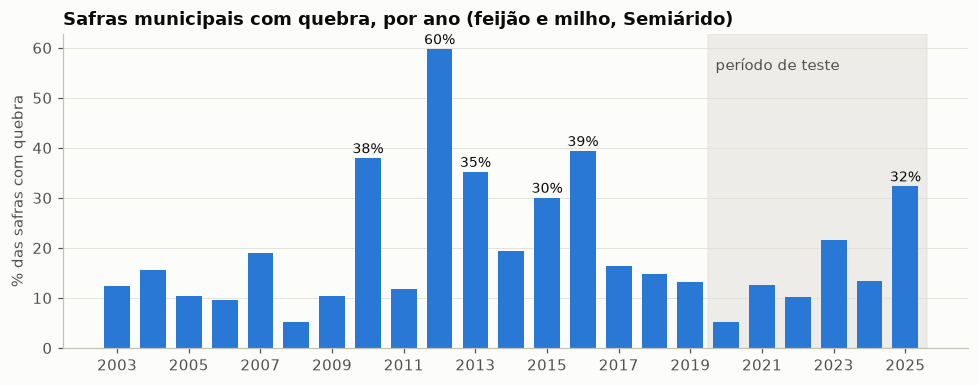

In [9]:
por_ano = base.groupby("ano")[ALVO].mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.6))
barras = ax.bar(por_ano.index, por_ano.values, width=0.72, color=AZUL)
ax.axvspan(ANO_CORTE + 0.5, por_ano.index.max() + 0.6, color=GRADE, alpha=0.55, zorder=0)
ax.text(ANO_CORTE + 0.7, por_ano.max() * 0.97, "período de teste", color=TINTA2, va="top")
for ano in por_ano[por_ano > 30].index:
    ax.text(ano, por_ano[ano] + 1, f"{por_ano[ano]:.0f}%", ha="center", fontsize=9)
ax.set_title("Safras municipais com quebra, por ano (feijão e milho, Semiárido)")
ax.set_ylabel("% das safras com quebra")
ax.set_xticks(por_ano.index[::2])
ax.grid(axis="x", visible=False)
salvar("01_quebra_por_ano")

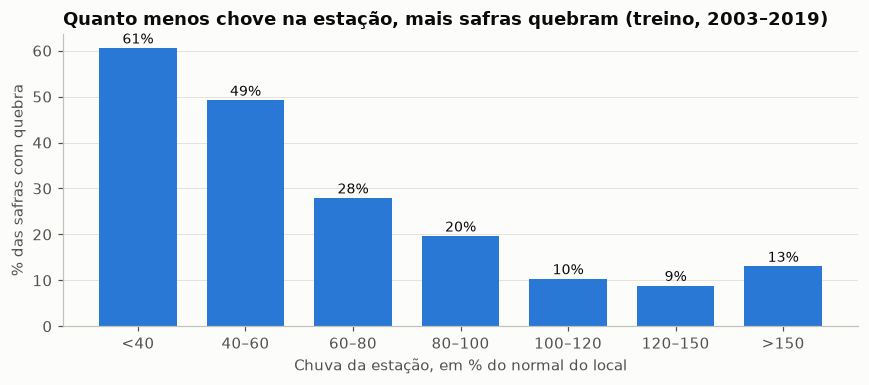

In [10]:
treino_eda = base[base["ano"] <= ANO_CORTE]  # exploração feita só com o período de treino
faixas = pd.cut(treino_eda["chuva_estacao_pct_normal"], [0, 40, 60, 80, 100, 120, 150, 1000],
                labels=["<40", "40–60", "60–80", "80–100", "100–120", "120–150", ">150"])
taxa_faixa = treino_eda.groupby(faixas, observed=True)[ALVO].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(taxa_faixa.index.astype(str), taxa_faixa["mean"] * 100, width=0.72, color=AZUL)
for i, (taxa, n) in enumerate(zip(taxa_faixa["mean"], taxa_faixa["size"])):
    ax.text(i, taxa * 100 + 1, f"{taxa:.0%}", ha="center", fontsize=9)
ax.set_title("Quanto menos chove na estação, mais safras quebram (treino, 2003–2019)")
ax.set_xlabel("Chuva da estação, em % do normal do local")
ax.set_ylabel("% das safras com quebra")
ax.grid(axis="x", visible=False)
salvar("02_quebra_por_chuva")

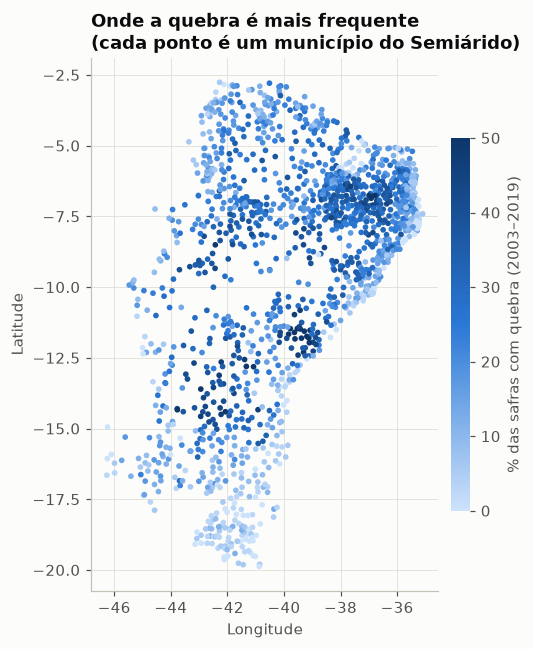

In [11]:
por_mun = treino_eda.groupby(["cod_mun", "latitude", "longitude"])[ALVO].mean().reset_index()
fig, ax = plt.subplots(figsize=(6.2, 6))
pontos = ax.scatter(por_mun["longitude"], por_mun["latitude"], c=por_mun[ALVO] * 100,
                    cmap=SEQ, s=14, vmin=0, vmax=50, linewidths=0)
cb = plt.colorbar(pontos, ax=ax, shrink=0.7, pad=0.02)
cb.set_label("% das safras com quebra (2003–2019)")
cb.outline.set_visible(False)
ax.set_title("Onde a quebra é mais frequente\n(cada ponto é um município do Semiárido)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_aspect("equal")
salvar("03_mapa_quebra")

**Leituras da exploração**

- A quebra é um fenômeno de **anos ruins**: a taxa varia de cerca de 5% a 60% conforme o ano,
  com pico na seca de 2012. Isso exige divisão temporal — embaralhar os anos deixaria o modelo
  "ver" a seca que deveria prever.
- A relação com a chuva é clara e monotônica, mas não determinística: mesmo com chuva normal uma
  parte das safras quebra (veranicos dentro do mês, pragas, problemas de manejo, erro de medida).
- A quebra é mais frequente no núcleo do sertão (interior de PB, RN, PE, CE, PI e norte da BA) e
  rara nas bordas mais úmidas (MG, ES, MA).
- As classes são desbalanceadas (cerca de 1 quebra para 4 safras normais): acurácia sozinha não
  serve como métrica e os modelos usam pesos de classe.

## 4. Divisão em treino, validação e teste

- **Treino: 2003–2019. Teste: 2020–2025.** A divisão é **cronológica**: o teste contém apenas
  anos posteriores a todos os anos de treino e só é usado uma vez, na avaliação final.
- **Validação cruzada temporal, somente no treino.** Cinco dobras em janela expansiva, com
  blocos de anos inteiros (a mesma lógica do `TimeSeriesSplit`, mas sem partir um ano ao meio):
  treina-se com os anos anteriores e valida-se no bloco seguinte.
- **Sem vazamento no pré-processamento.** Imputação, padronização e codificação ficam dentro de
  um `Pipeline`; em cada dobra são ajustadas apenas com a parte de treino daquela dobra.

In [12]:
treino = base[base["ano"] <= ANO_CORTE].reset_index(drop=True)
teste = base[base["ano"] > ANO_CORTE].reset_index(drop=True)
X_treino, y_treino = treino[PREDITORAS], treino[ALVO]
X_teste, y_teste = teste[PREDITORAS], teste[ALVO]

BLOCOS_VALIDACAO = [(2010, 2011), (2012, 2013), (2014, 2015), (2016, 2017), (2018, 2019)]
anos_treino = treino["ano"].to_numpy()
DOBRAS = [(np.where(anos_treino < ini)[0], np.where((anos_treino >= ini) & (anos_treino <= fim))[0])
          for ini, fim in BLOCOS_VALIDACAO]

print(f"Treino: {len(treino):,} linhas, {treino['ano'].min()}–{treino['ano'].max()}, "
      f"quebra em {y_treino.mean():.1%}")
print(f"Teste:  {len(teste):,} linhas, {teste['ano'].min()}–{teste['ano'].max()}, "
      f"quebra em {y_teste.mean():.1%}\n")
for (ini, fim), (i_tr, i_va) in zip(BLOCOS_VALIDACAO, DOBRAS):
    print(f"dobra: treina {anos_treino[i_tr].min()}–{anos_treino[i_tr].max()} ({len(i_tr):,}) "
          f"→ valida {ini}–{fim} ({len(i_va):,}, quebra {y_treino.iloc[i_va].mean():.0%})")

Treino: 48,926 linhas, 2003–2019, quebra em 21.0%
Teste:  17,310 linhas, 2020–2025, quebra em 15.9%

dobra: treina 2003–2009 (20,396) → valida 2010–2011 (5,793, quebra 25%)
dobra: treina 2003–2011 (26,189) → valida 2012–2013 (5,466, quebra 48%)
dobra: treina 2003–2013 (31,655) → valida 2014–2015 (5,727, quebra 25%)
dobra: treina 2003–2015 (37,382) → valida 2016–2017 (5,754, quebra 28%)
dobra: treina 2003–2017 (43,136) → valida 2018–2019 (5,790, quebra 14%)


## 5. Treinamento dos modelos

Três modelos supervisionados, do mais simples ao mais flexível:

| Modelo | Por que foi incluído |
|---|---|
| **Regressão Logística** | Linha de base linear e interpretável; mostra quanto se ganha com modelos não lineares |
| **Random Forest** | Captura interações (por exemplo, pouca chuva *e* solo já seco) e é robusto a ruído |
| **Gradient Boosting** (`HistGradientBoosting`) | Costuma ser o melhor em dados tabulares; corrige erros árvore a árvore |

Os hiperparâmetros são escolhidos por `GridSearchCV` com as dobras temporais, otimizando a
**PR-AUC** (área sob a curva precisão–recall), adequada a classes desbalanceadas. Também
avaliamos duas referências sem aprendizado, para saber se o ML realmente acrescenta algo:
uma **regra da chuva** ("alertar quando a chuva da estação fica abaixo de X% do normal") e a
taxa histórica de quebra.

In [13]:
def preprocessador(numericas, padronizar):
    etapas_num = [("imputar", SimpleImputer(strategy="median"))]
    if padronizar:
        etapas_num.append(("padronizar", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(etapas_num), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])


ESTIMADORES = {
    "Regressão Logística": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
        {"modelo__C": [0.01, 0.1, 1.0]}, True),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                               n_jobs=-1, random_state=SEED),
        {"modelo__min_samples_leaf": [5, 20], "modelo__max_features": ["sqrt", 0.3]}, False),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=SEED),
        {"modelo__learning_rate": [0.03, 0.1], "modelo__max_leaf_nodes": [8, 31]}, False),
}
COR = {"Regressão Logística": AZUL, "Random Forest": LARANJA, "Gradient Boosting": VERDE}


def criar_pipeline(nome, numericas=NUMERICAS):
    estimador, _, padronizar = ESTIMADORES[nome]
    return Pipeline([("pre", preprocessador(numericas, padronizar)), ("modelo", clone(estimador))])


buscas = {}
for nome, (_, grade_hp, _) in ESTIMADORES.items():
    busca = GridSearchCV(criar_pipeline(nome), grade_hp, cv=DOBRAS, scoring="average_precision",
                         n_jobs=1 if nome == "Random Forest" else 5, refit=True)
    busca.fit(X_treino, y_treino)
    buscas[nome] = busca
    melhor = {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()}
    print(f"{nome:<20} PR-AUC média na validação = {busca.best_score_:.3f}  | melhores: {melhor}")

Regressão Logística  PR-AUC média na validação = 0.489  | melhores: {'C': 0.01}


Random Forest        PR-AUC média na validação = 0.471  | melhores: {'max_features': 'sqrt', 'min_samples_leaf': 5}


Gradient Boosting    PR-AUC média na validação = 0.497  | melhores: {'learning_rate': 0.03, 'max_leaf_nodes': 8}


### Escolha do limiar de decisão (ainda só com o treino)

Os modelos devolvem uma probabilidade; o alerta precisa de um ponto de corte. Como **deixar de
avisar uma quebra é mais grave do que um alerta falso** (ver seção 8), o limiar de cada modelo é
fixado para atingir **recall de 75%** nas previsões *fora da amostra* da validação cruzada
(cada ano previsto por um modelo que nunca o viu). O teste não participa dessa escolha.

In [14]:
RECALL_ALVO = 0.75
idx_validacao = np.concatenate([i_va for _, i_va in DOBRAS])
y_validacao = y_treino.iloc[idx_validacao]


def limiar_para_recall(y, pontuacao, alvo=RECALL_ALVO):
    """Maior limiar cuja sensibilidade (recall) ainda atinge o alvo."""
    _, recall, limiares = precision_recall_curve(y, pontuacao)
    return limiares[np.where(recall[:-1] >= alvo)[0][-1]]


def previsoes_fora_da_amostra(pipeline, X=X_treino):
    partes = [clone(pipeline).fit(X.iloc[i_tr], y_treino.iloc[i_tr]).predict_proba(X.iloc[i_va])[:, 1]
              for i_tr, i_va in DOBRAS]
    return np.concatenate(partes)


limiares, prob_validacao = {}, {}
for nome, busca in buscas.items():
    prob_validacao[nome] = previsoes_fora_da_amostra(busca.best_estimator_)
    limiares[nome] = limiar_para_recall(y_validacao, prob_validacao[nome])
    print(f"{nome:<20} limiar = {limiares[nome]:.3f}")

# Regra da chuva: pontuação = quanto a chuva da estação ficou abaixo do normal
regra = lambda df: -df["chuva_estacao_pct_normal"].fillna(100)
limiar_regra = limiar_para_recall(y_validacao, regra(treino.iloc[idx_validacao]))
print(f"{'Regra da chuva':<20} alerta quando a chuva da estação fica abaixo de "
      f"{-limiar_regra:.0f}% do normal")

Regressão Logística  limiar = 0.571


Random Forest        limiar = 0.296


Gradient Boosting    limiar = 0.509
Regra da chuva       alerta quando a chuva da estação fica abaixo de 87% do normal


## 6. Avaliação dos modelos

Métricas no **conjunto de teste (2020–2025)**, nunca usado até aqui:

- **Recall**: das quebras que aconteceram, quantas o modelo avisou;
- **Precisão**: dos alertas emitidos, quantos se confirmaram;
- **F1**: equilíbrio entre os dois; **Acurácia**: acertos totais (pouco informativa aqui, pois
  prever "nunca quebra" já acertaria a maioria);
- **PR-AUC** e **ROC-AUC**: qualidade do ordenamento de risco, independente do limiar.

In [15]:
def metricas(y, pontuacao, limiar):
    previsto = (pontuacao >= limiar).astype(int)
    return {
        "Recall": recall_score(y, previsto), "Precisão": precision_score(y, previsto),
        "F1": f1_score(y, previsto), "Acurácia": accuracy_score(y, previsto),
        "PR-AUC": average_precision_score(y, pontuacao), "ROC-AUC": roc_auc_score(y, pontuacao),
        "% de safras alertadas": previsto.mean(),
    }


prob_teste = {nome: busca.predict_proba(X_teste)[:, 1] for nome, busca in buscas.items()}

linhas_val, linhas_teste = {}, {}
for nome in buscas:
    linhas_val[nome] = metricas(y_validacao, prob_validacao[nome], limiares[nome])
    linhas_teste[nome] = metricas(y_teste, prob_teste[nome], limiares[nome])
linhas_val["Regra da chuva"] = metricas(y_validacao, regra(treino.iloc[idx_validacao]), limiar_regra)
linhas_teste["Regra da chuva"] = metricas(y_teste, regra(teste), limiar_regra)

resultado_val = pd.DataFrame(linhas_val).T
resultado_val.insert(4, "PR-AUC média das dobras",
                     pd.Series({nome: busca.best_score_ for nome, busca in buscas.items()}))
resultado_teste = pd.DataFrame(linhas_teste).T
print("Validação cruzada temporal (treino, anos 2010–2019). 'PR-AUC' junta os cinco blocos; "
      "'PR-AUC média das dobras' é o critério usado na busca de hiperparâmetros.")
display(resultado_val.round(3))
print(f"TESTE (2020–2025) — taxa real de quebra: {y_teste.mean():.1%} "
      f"(é a PR-AUC de um modelo sem informação)")
display(resultado_teste.round(3))

Validação cruzada temporal (treino, anos 2010–2019). 'PR-AUC' junta os cinco blocos; 'PR-AUC média das dobras' é o critério usado na busca de hiperparâmetros.


,Recall,Precisão,F1,Acurácia,PR-AUC média das dobras,PR-AUC,ROC-AUC,% de safras alertadas
Regressão Logística,0.750,0.444,0.558,0.672,0.489,0.564,0.760,0.466
Random Forest,0.750,0.414,0.534,0.638,0.471,0.463,0.727,0.499
Gradient Boosting,0.750,0.442,0.556,0.670,0.497,0.526,0.758,0.468
Regra da chuva,0.750,0.370,0.496,0.579,NaN,0.458,0.695,0.559


TESTE (2020–2025) — taxa real de quebra: 15.9% (é a PR-AUC de um modelo sem informação)


,Recall,Precisão,F1,Acurácia,PR-AUC,ROC-AUC,% de safras alertadas
Regressão Logística,0.551,0.320,0.405,0.742,0.337,0.738,0.274
Random Forest,0.650,0.266,0.377,0.659,0.329,0.714,0.389
Gradient Boosting,0.600,0.306,0.405,0.720,0.371,0.742,0.312
Regra da chuva,0.578,0.199,0.296,0.564,0.207,0.601,0.461


## 7. Visualizações explicativas

### 7.1 Comparação de desempenho entre os modelos

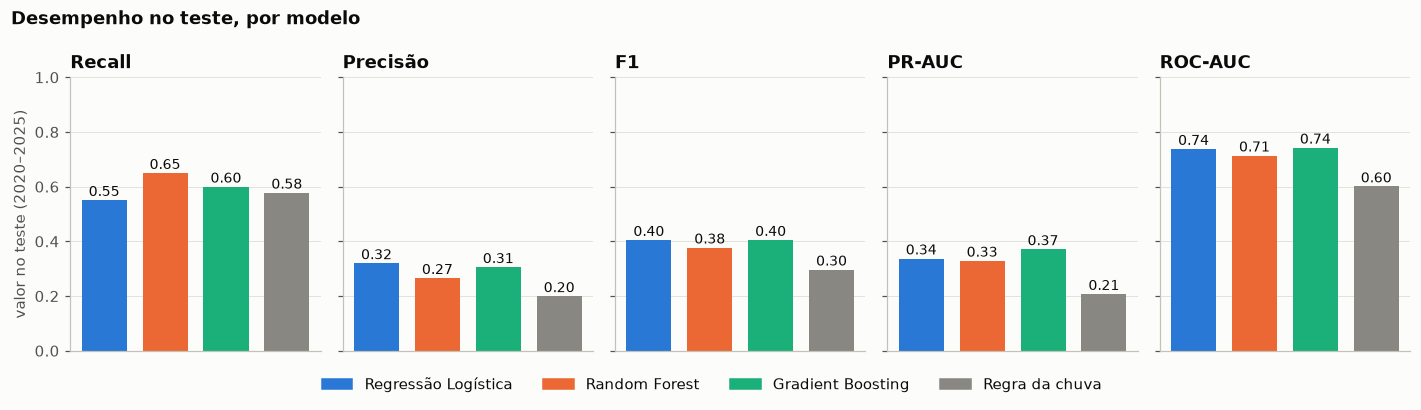

In [16]:
ordem = list(buscas) + ["Regra da chuva"]
cores = [COR.get(n, CINZA) for n in ordem]
mets = ["Recall", "Precisão", "F1", "PR-AUC", "ROC-AUC"]

fig, eixos = plt.subplots(1, len(mets), figsize=(13, 3.4), sharey=True)
for ax, met in zip(eixos, mets):
    valores = resultado_teste.loc[ordem, met]
    ax.bar(range(len(ordem)), valores, color=cores, width=0.74)
    for i, v in enumerate(valores):
        ax.text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=9)
    ax.set_title(met)
    ax.set_xticks([])
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
eixos[0].set_ylabel("valor no teste (2020–2025)")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cores], ordem, ncol=4,
           loc="lower center", bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Desempenho no teste, por modelo", x=0.01, ha="left", fontweight="bold")
salvar("04_comparacao_modelos")

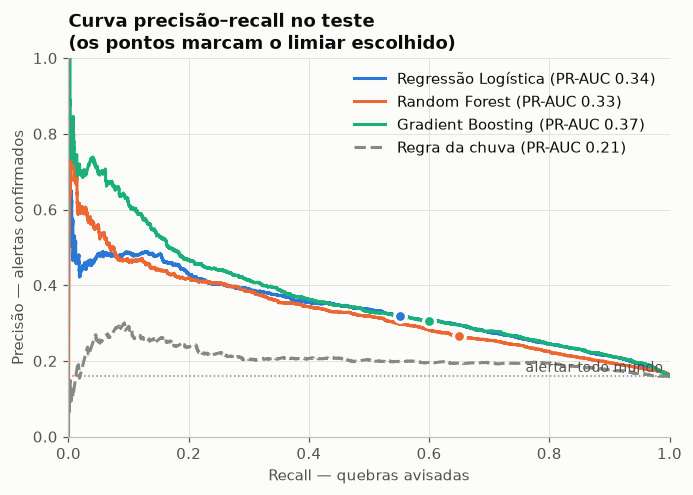

In [17]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for nome in buscas:
    precisao, recall, _ = precision_recall_curve(y_teste, prob_teste[nome])
    ax.plot(recall, precisao, color=COR[nome], lw=2,
            label=f"{nome} (PR-AUC {resultado_teste.loc[nome, 'PR-AUC']:.2f})")
    ax.scatter(resultado_teste.loc[nome, "Recall"], resultado_teste.loc[nome, "Precisão"],
               color=COR[nome], s=60, zorder=3, edgecolor="#fcfcfb", linewidth=2)
precisao, recall, _ = precision_recall_curve(y_teste, regra(teste))
ax.plot(recall, precisao, color=CINZA, lw=2, ls="--",
        label=f"Regra da chuva (PR-AUC {resultado_teste.loc['Regra da chuva', 'PR-AUC']:.2f})")
ax.axhline(y_teste.mean(), color=CINZA, lw=1, ls=":")
ax.text(0.99, y_teste.mean() + 0.012, "alertar todo mundo", ha="right", color=TINTA2, fontsize=9)
ax.set_title("Curva precisão–recall no teste\n(os pontos marcam o limiar escolhido)")
ax.set_xlabel("Recall — quebras avisadas")
ax.set_ylabel("Precisão — alertas confirmados")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc="upper right")
salvar("05_curva_precisao_recall")

### 7.2 Matrizes de confusão (teste)

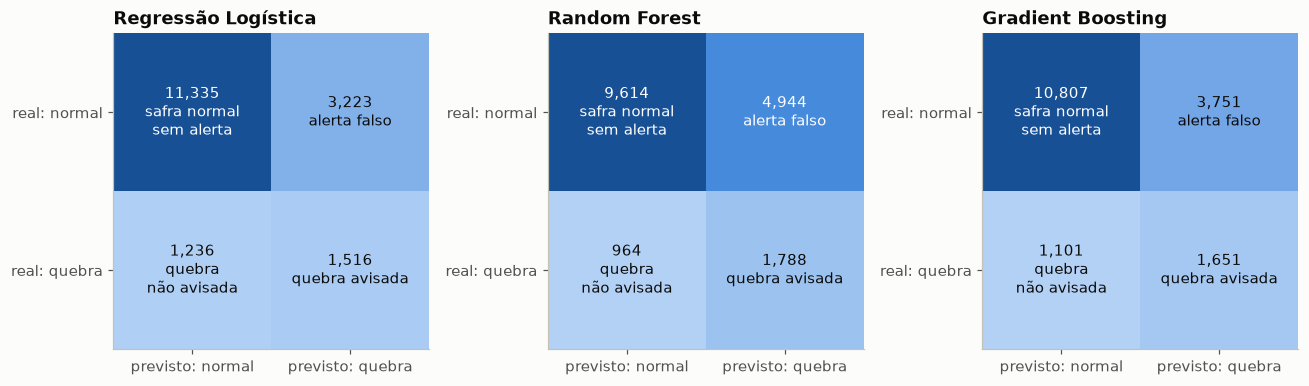

In [18]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, nome in zip(eixos, buscas):
    mc = confusion_matrix(y_teste, (prob_teste[nome] >= limiares[nome]).astype(int))
    ax.imshow(mc, cmap=SEQ, vmin=0, vmax=mc.max() * 1.25)
    rotulos = [["safra normal\nsem alerta", "alerta falso"], ["quebra\nnão avisada", "quebra avisada"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{mc[i, j]:,}\n{rotulos[i][j]}", ha="center", va="center",
                    color="white" if mc[i, j] > mc.max() * 0.5 else TINTA, fontsize=10)
    ax.set_xticks([0, 1], ["previsto: normal", "previsto: quebra"])
    ax.set_yticks([0, 1], ["real: normal", "real: quebra"])
    ax.set_title(nome)
    ax.grid(False)
salvar("06_matrizes_confusao")

### 7.3 Importância das variáveis

Importância por permutação no teste: quanto a PR-AUC cai quando os valores de uma variável são
embaralhados. Diferente da importância interna das árvores, ela mede o efeito sobre dados novos
e trata cada variável categórica como um todo.

Modelo com melhor PR-AUC média nas dobras de validação: Gradient Boosting


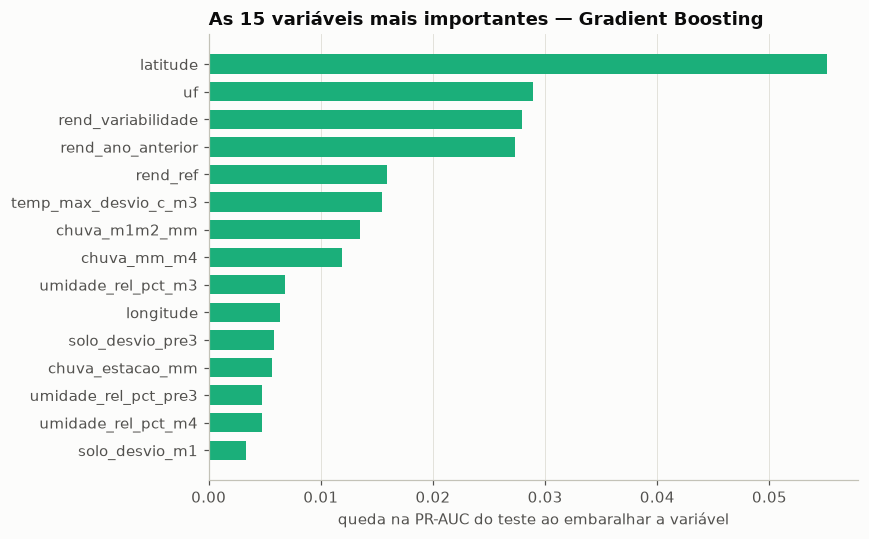


Importância somada por grupo de variáveis:
Localização e calendário    0.091
Histórico do município      0.071
Clima da estação chuvosa    0.055
Clima antes das chuvas     -0.006


In [19]:
# O modelo é escolhido pela validação (mesmo critério da busca de hiperparâmetros), não pelo teste
MELHOR = max(buscas, key=lambda nome: buscas[nome].best_score_)
print("Modelo com melhor PR-AUC média nas dobras de validação:", MELHOR)

imp = permutation_importance(buscas[MELHOR].best_estimator_, X_teste, y_teste,
                             scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=5)
importancia = pd.Series(imp.importances_mean, index=PREDITORAS).sort_values(ascending=False)

top = importancia.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=COR[MELHOR], height=0.7)
ax.set_title(f"As 15 variáveis mais importantes — {MELHOR}")
ax.set_xlabel("queda na PR-AUC do teste ao embaralhar a variável")
ax.grid(axis="y", visible=False)
salvar("07_importancia_variaveis")

grupo = lambda c: ("Histórico do município" if c in HISTORICO[:5] else
                   "Localização e calendário" if c in HISTORICO[5:] + CATEGORICAS else
                   "Clima antes das chuvas" if "pre" in c else "Clima da estação chuvosa")
print("\nImportância somada por grupo de variáveis:")
print(importancia.groupby(grupo).sum().sort_values(ascending=False).round(4).to_string())

### 7.4 Com quanta antecedência dá para avisar?

O mesmo tipo de modelo, com os mesmos hiperparâmetros, é reajustado usando apenas a informação
disponível em cada cenário da seção 3.5. O limiar de cada cenário segue a mesma regra
(recall de 75% na validação).

,Recall,Precisão,F1,Acurácia,PR-AUC,ROC-AUC,% de safras alertadas
A — antes do plantio,0.739,0.197,0.312,0.480,0.246,0.644,0.596
B — meio da estação,0.738,0.239,0.361,0.585,0.294,0.697,0.491
C — fim da estação,0.600,0.306,0.405,0.720,0.371,0.742,0.312


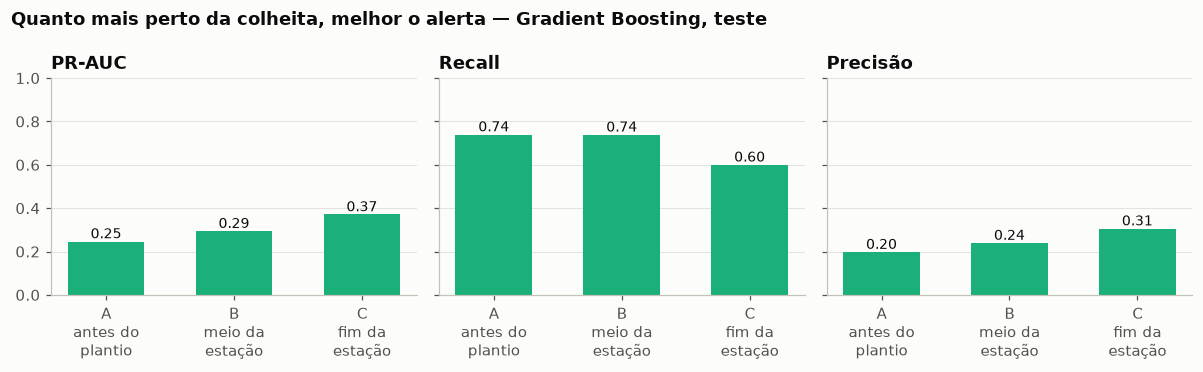

In [20]:
linhas_cenario = {}
for cenario, numericas in CENARIOS.items():
    pipe = criar_pipeline(MELHOR, numericas).set_params(**buscas[MELHOR].best_params_)
    cols = numericas + CATEGORICAS
    limiar = limiar_para_recall(y_validacao, previsoes_fora_da_amostra(pipe, X_treino[cols]))
    prob = pipe.fit(X_treino[cols], y_treino).predict_proba(X_teste[cols])[:, 1]
    linhas_cenario[cenario] = metricas(y_teste, prob, limiar)
resultado_cenarios = pd.DataFrame(linhas_cenario).T
display(resultado_cenarios.round(3))

fig, eixos = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, met in zip(eixos, ["PR-AUC", "Recall", "Precisão"]):
    valores = resultado_cenarios[met]
    ax.bar(range(3), valores, color=COR[MELHOR], width=0.6)
    for i, v in enumerate(valores):
        ax.text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=9)
    ax.set_xticks(range(3), ["A\nantes do\nplantio", "B\nmeio da\nestação", "C\nfim da\nestação"])
    ax.set_title(met); ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)
fig.suptitle(f"Quanto mais perto da colheita, melhor o alerta — {MELHOR}, teste",
             x=0.01, ha="left", fontweight="bold")
salvar("08_antecedencia")

### 7.5 O alerta acompanha os anos ruins?

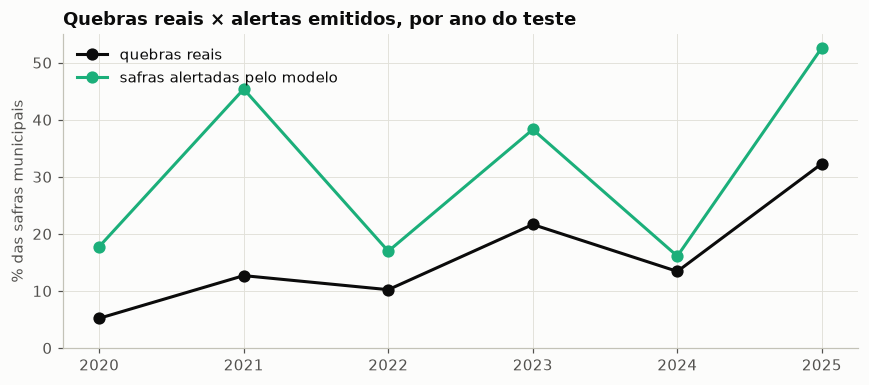

ano,2020,2021,2022,2023,2024,2025
quebra_real,5.200,12.700,10.200,21.600,13.400,32.300
alertadas,17.800,45.400,17.000,38.300,16.100,52.600


In [21]:
teste_av = teste.assign(prob=prob_teste[MELHOR],
                        alerta=(prob_teste[MELHOR] >= limiares[MELHOR]).astype(int))
anual = teste_av.groupby("ano").agg(quebra_real=(ALVO, "mean"), alertadas=("alerta", "mean")) * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(anual.index, anual["quebra_real"], color=TINTA, lw=2, marker="o", ms=7, label="quebras reais")
ax.plot(anual.index, anual["alertadas"], color=COR[MELHOR], lw=2, marker="o", ms=7,
        label="safras alertadas pelo modelo")
ax.set_title("Quebras reais × alertas emitidos, por ano do teste")
ax.set_ylabel("% das safras municipais")
ax.set_ylim(0, None); ax.set_xticks(anual.index)
ax.legend(loc="upper left")
salvar("09_alertas_por_ano")
display(anual.round(1).T)

### 7.6 O modelo trata todos os grupos igualmente?

Recall e precisão do melhor modelo, no teste, por estado e por porte da lavoura municipal
(quartis de área plantada no ano anterior). Diferenças grandes indicam grupos mal atendidos.

,safras,quebras,% quebra,Recall,Precisão,% alertadas
uf,,,,,,
ES,72.000,1.000,0.010,0.000,NaN,0.000
SE,332.000,14.000,0.040,0.070,0.140,0.020
MG,"2,538.000",60.000,0.020,0.080,0.040,0.050
CE,"2,100.000",338.000,0.160,0.300,0.270,0.180
AL,499.000,42.000,0.080,0.330,0.290,0.100
RN,"1,743.000",371.000,0.210,0.460,0.410,0.240
PE,"1,490.000",251.000,0.170,0.570,0.290,0.330
PI,"2,592.000",499.000,0.190,0.650,0.320,0.390
MA,192.000,3.000,0.020,0.670,0.120,0.080


,safras,quebras,% quebra,Recall,Precisão,% alertadas
porte,,,,,,
Q1 (menores),"4,328.000",474.000,0.110,0.490,0.290,0.180
Q2,"4,340.000",746.000,0.170,0.660,0.330,0.340
Q3,"4,317.000",766.000,0.180,0.630,0.300,0.380
Q4 (maiores),"4,325.000",766.000,0.180,0.580,0.300,0.350


,safras,quebras,% quebra,Recall,Precisão,% alertadas
cultura,,,,,,
feijao,"8,684.000","1,340.000",0.150,0.510,0.300,0.260
milho,"8,626.000","1,412.000",0.160,0.680,0.310,0.360


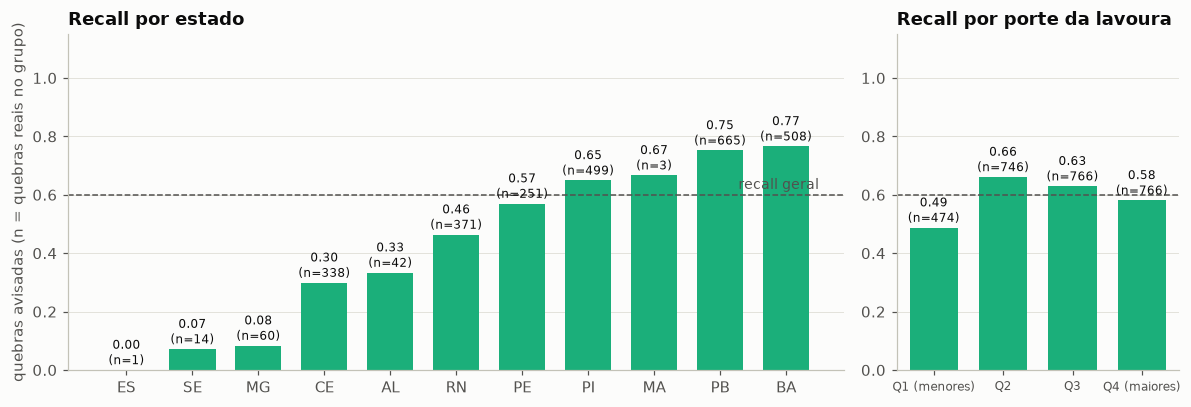

In [22]:
def por_grupo(df, coluna):
    def resumo(g):
        return pd.Series({
            "safras": len(g), "quebras": int(g[ALVO].sum()), "% quebra": g[ALVO].mean(),
            "Recall": recall_score(g[ALVO], g["alerta"], zero_division=np.nan),
            "Precisão": precision_score(g[ALVO], g["alerta"], zero_division=np.nan),
            "% alertadas": g["alerta"].mean()})
    return df.groupby(coluna, observed=True).apply(resumo)


teste_av["porte"] = pd.qcut(teste_av["log_area_plantada_ant"], 4,
                            labels=["Q1 (menores)", "Q2", "Q3", "Q4 (maiores)"])
vies_uf = por_grupo(teste_av, "uf").sort_values("Recall")
vies_porte = por_grupo(teste_av, "porte")
vies_cultura = por_grupo(teste_av, "cultura")
display(vies_uf.round(2)); display(vies_porte.round(2)); display(vies_cultura.round(2))

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [11, 4]})
for ax, tab, titulo in [(eixos[0], vies_uf, "Recall por estado"),
                        (eixos[1], vies_porte, "Recall por porte da lavoura")]:
    ax.bar(tab.index.astype(str), tab["Recall"], color=COR[MELHOR], width=0.7)
    for i, (r, n) in enumerate(zip(tab["Recall"], tab["quebras"])):
        ax.text(i, (r if r == r else 0) + 0.02, f"{r:.2f}\n(n={int(n)})", ha="center", fontsize=8)
    ax.axhline(resultado_teste.loc[MELHOR, "Recall"], color=TINTA2, lw=1, ls="--")
    ax.set_title(titulo); ax.set_ylim(0, 1.15); ax.grid(axis="x", visible=False)
eixos[1].tick_params(axis="x", labelsize=8)
eixos[0].set_ylabel("quebras avisadas (n = quebras reais no grupo)")
eixos[0].text(len(vies_uf) - 0.5, resultado_teste.loc[MELHOR, "Recall"] + 0.02,
              "recall geral", ha="right", color=TINTA2, fontsize=9)
salvar("10_recall_por_grupo")

### 7.7 Calibração: transformar a pontuação em probabilidade

Até aqui o modelo foi usado para **ordenar** as lavouras por risco. A pontuação que ele devolve,
porém, não pode ser lida como probabilidade: os pesos de classe (`class_weight="balanced"`) fazem
o modelo tratar quebras e safras normais como se fossem igualmente frequentes, e isso infla as
pontuações. Para dizer ao agricultor “a chance de quebra é de 40%”, é preciso **calibrar**.

**Dois métodos candidatos**, ambos ajustados só com as previsões fora da amostra do treino
(cada ano previsto por um modelo que não o viu):

- **Platt (sigmoide):** uma regressão logística de uma variável sobre o logit da pontuação,
  $p = \sigma(a \cdot \mathrm{logit}(s) + b)$. Tem dois parâmetros, é estritamente crescente e,
  portanto, **não altera a ordem** das lavouras.
- **Isotônica:** uma função em degraus, não decrescente, ajustada por mínimos quadrados. É mais
  flexível, mas cria empates (muitas lavouras com exatamente a mesma probabilidade).

**Escolha do método, ainda dentro do treino:** cada método é ajustado nos blocos de validação
anteriores e avaliado no bloco seguinte (2014–15, 2016–17 e 2018–19). Vence o de menor
**escore de Brier** médio, $\mathrm{Brier} = \frac{1}{n}\sum_i (p_i - y_i)^2$, que mede o erro
quadrático da probabilidade. O teste não participa da escolha.

In [23]:
from IPython.display import Markdown
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss


def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def ajustar_platt(pontuacao, y):
    reg = LogisticRegression(C=1e6, max_iter=1000).fit(logit(pontuacao).reshape(-1, 1), y)
    funcao = lambda s: reg.predict_proba(logit(s).reshape(-1, 1))[:, 1]
    return funcao, float(reg.coef_[0, 0]), float(reg.intercept_[0])


def ajustar_isotonica(pontuacao, y):
    reg = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(pontuacao, y)
    return (lambda s: reg.predict(np.asarray(s, dtype=float))), None, None


def erro_calibracao(y, p, faixas=10):
    """ECE: média, ponderada pelo tamanho, de |frequência observada − probabilidade média| por decil."""
    tab = (pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
           .assign(faixa=lambda d: pd.qcut(d["p"], faixas, duplicates="drop"))
           .groupby("faixa", observed=True).agg(y=("y", "mean"), p=("p", "mean"), n=("y", "size")))
    return float((tab["n"] / tab["n"].sum() * (tab["y"] - tab["p"]).abs()).sum())


METODOS = {"Platt (sigmoide)": ajustar_platt, "Isotônica": ajustar_isotonica}
pont_val, pont_teste = prob_validacao[MELHOR], prob_teste[MELHOR]
y_val = y_validacao.to_numpy()
bloco_val = np.concatenate([[k] * len(i_va) for k, (_, i_va) in enumerate(DOBRAS)])

linhas_escolha = {}
for nome_met, ajustar in METODOS.items():
    brier_blocos = []
    for k in range(2, len(DOBRAS)):                      # calibra nos blocos anteriores, avalia no bloco k
        antes, este = bloco_val < k, bloco_val == k
        calibrar_k, _, _ = ajustar(pont_val[antes], y_val[antes])
        brier_blocos.append(brier_score_loss(y_val[este], calibrar_k(pont_val[este])))
    linhas_escolha[nome_met] = {f"Brier em {BLOCOS_VALIDACAO[k][0]}–{BLOCOS_VALIDACAO[k][1]}": b
                                for k, b in zip(range(2, len(DOBRAS)), brier_blocos)}
    linhas_escolha[nome_met]["Brier médio"] = float(np.mean(brier_blocos))
escolha_calibracao = pd.DataFrame(linhas_escolha).T
METODO_CALIBRACAO = escolha_calibracao["Brier médio"].idxmin()
print("Escolha do método de calibração (só com o treino; menor é melhor):")
display(escolha_calibracao.round(4))
print("Método escolhido:", METODO_CALIBRACAO)

calibrar, coef_a, coef_b = METODOS[METODO_CALIBRACAO](pont_val, y_val)   # ajuste final: toda a validação
if coef_a is not None:
    print(f"p = sigmoide({coef_a:.3f} × logit(pontuação) + ({coef_b:.3f}))")
limiar_calibrado = float(calibrar([limiares[MELHOR]])[0])
print(f"O limiar de alerta ({limiares[MELHOR]:.3f} na pontuação) equivale a {limiar_calibrado:.1%} de probabilidade calibrada.")

Escolha do método de calibração (só com o treino; menor é melhor):


,Brier em 2014–2015,Brier em 2016–2017,Brier em 2018–2019,Brier médio
Platt (sigmoide),0.219,0.179,0.114,0.171
Isotônica,0.226,0.180,0.114,0.173


Método escolhido: Platt (sigmoide)
p = sigmoide(0.871 × logit(pontuação) + (-1.118))
O limiar de alerta (0.509 na pontuação) equivale a 25.2% de probabilidade calibrada.


**Avaliação no teste.** Além do Brier, usamos:

- o **erro de calibração esperado (ECE)**: as lavouras são divididas em dez grupos de mesmo
  tamanho pela probabilidade prevista; em cada grupo compara-se a probabilidade média com a
  frequência real de quebra, e tira-se a média das diferenças absolutas;
- o **índice de habilidade de Brier**, $1 - \mathrm{Brier} / \mathrm{Brier}_{ref}$, em que a
  referência é prever para todas as lavouras a taxa de quebra do treino. Zero significa “não
  melhor que a média histórica”; um, previsão perfeita.

Teste (2020–2025). Brier de referência (prever sempre 21%): 0.1363


,Probabilidade média prevista,Frequência real de quebra,Brier,ECE,Habilidade de Brier,PR-AUC,Valores distintos
Pontuação bruta (com pesos de classe),0.386,0.159,0.183,0.227,-0.346,0.371,"6,968.000"
Calibrada — Platt (sigmoide),0.204,0.159,0.122,0.046,0.106,0.371,"5,003.000"
Alternativa — Isotônica,0.204,0.159,0.122,0.047,0.102,0.359,74.000


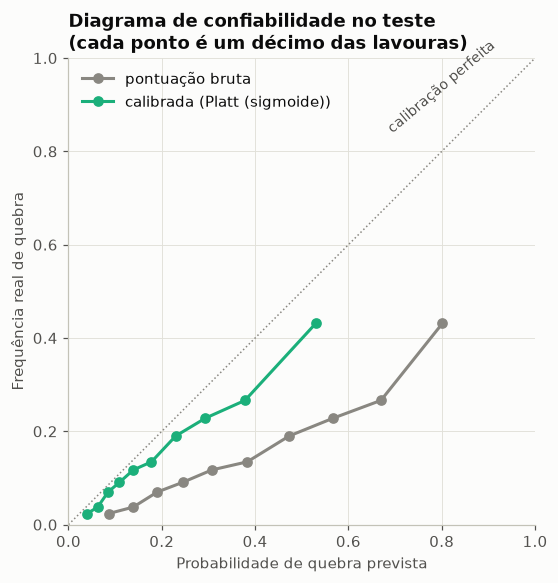

Probabilidade calibrada × frequência real, por décimo das lavouras (teste):


,prevista,real,lavouras
décimo,,,
0,0.040,0.024,1731
1,0.063,0.038,1731
2,0.085,0.070,1731
3,0.109,0.091,1731
4,0.139,0.117,1731
5,0.178,0.135,1731
6,0.230,0.190,1731
7,0.293,0.228,1731
8,0.378,0.266,1731


Média prevista × frequência real, por ano:


ano,2020,2021,2022,2023,2024,2025
prevista,0.135,0.260,0.157,0.226,0.152,0.298
real,0.052,0.127,0.102,0.216,0.134,0.323


In [24]:
y_te = y_teste.to_numpy()
prob_cal = calibrar(pont_teste)
versoes = {"Pontuação bruta (com pesos de classe)": pont_teste, f"Calibrada — {METODO_CALIBRACAO}": prob_cal}
outro = next(m for m in METODOS if m != METODO_CALIBRACAO)
versoes[f"Alternativa — {outro}"] = METODOS[outro](pont_val, y_val)[0](pont_teste)
brier_ref = brier_score_loss(y_te, np.full(len(y_te), y_treino.mean()))
tabela_calibracao = pd.DataFrame({
    nome_v: {"Probabilidade média prevista": p.mean(), "Frequência real de quebra": y_te.mean(),
             "Brier": brier_score_loss(y_te, p), "ECE": erro_calibracao(y_te, p),
             "Habilidade de Brier": 1 - brier_score_loss(y_te, p) / brier_ref,
             "PR-AUC": average_precision_score(y_te, p), "Valores distintos": len(np.unique(np.round(p, 4)))}
    for nome_v, p in versoes.items()}).T
print(f"Teste (2020–2025). Brier de referência (prever sempre {y_treino.mean():.0%}): {brier_ref:.4f}")
display(tabela_calibracao.round(4))

def curva_confiabilidade(p):
    return (pd.DataFrame({"y": y_te, "p": p}).assign(faixa=lambda d: pd.qcut(d["p"], 10, duplicates="drop"))
            .groupby("faixa", observed=True).agg(prevista=("p", "mean"), real=("y", "mean"), lavouras=("y", "size")))

conf_bruta, conf_cal = curva_confiabilidade(pont_teste), curva_confiabilidade(prob_cal)
fig, ax = plt.subplots(figsize=(6.2, 5.4))
ax.plot([0, 1], [0, 1], color=CINZA, lw=1, ls=":")
ax.text(0.80, 0.84, "calibração perfeita", color=TINTA2, fontsize=9, rotation=40, ha="center")
ax.plot(conf_bruta["prevista"], conf_bruta["real"], color=CINZA, lw=2, marker="o", ms=6, label="pontuação bruta")
ax.plot(conf_cal["prevista"], conf_cal["real"], color=COR[MELHOR], lw=2, marker="o", ms=6,
        label=f"calibrada ({METODO_CALIBRACAO})")
ax.set_title("Diagrama de confiabilidade no teste\n(cada ponto é um décimo das lavouras)")
ax.set_xlabel("Probabilidade de quebra prevista")
ax.set_ylabel("Frequência real de quebra")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.legend(loc="upper left")
salvar("11_calibracao")

print("Probabilidade calibrada × frequência real, por décimo das lavouras (teste):")
display(conf_cal.reset_index(drop=True).rename_axis("décimo").round(3))
por_ano_cal = (pd.DataFrame({"ano": teste["ano"].to_numpy(), "prevista": prob_cal, "real": y_te})
               .groupby("ano").mean().round(3))
print("Média prevista × frequência real, por ano:")
display(por_ano_cal.T)

teste_av["prob_calibrada"] = prob_cal

In [25]:
tc = tabela_calibracao
bruta, cal = tc.iloc[0], tc.iloc[1]
topo = conf_cal.iloc[-1]
display(Markdown(f"""
**Leitura da calibração**

- **A pontuação bruta superestimava muito o risco:** previa em média {bruta['Probabilidade média prevista']:.0%}
  de chance de quebra, contra {bruta['Frequência real de quebra']:.0%} de quebras reais. Depois de calibrada, a
  média prevista é de {cal['Probabilidade média prevista']:.0%}.
- **O erro caiu:** Brier de {bruta['Brier']:.3f} para {cal['Brier']:.3f} e ECE de {bruta['ECE']:.3f} para
  {cal['ECE']:.3f}. A pontuação bruta era pior que prever a média histórica para todo mundo
  (habilidade de {bruta['Habilidade de Brier']:.2f}); a calibrada é melhor
  ({cal['Habilidade de Brier']:.2f}), embora o ganho sobre a média seja modesto.
- **A ordem das lavouras não muda** com o método escolhido, então recall, precisão e PR-AUC
  ({cal['PR-AUC']:.2f}) são os mesmos de antes. O alerta continua sendo emitido para as mesmas
  lavouras; em probabilidade, o limiar passa a ser {limiar_calibrado:.0%}.
- **A probabilidade ainda fica um pouco alta:** depois de calibrada, ela continua acima da
  frequência real. No décimo de maior risco, a previsão média é {topo['prevista']:.0%} e
  {topo['real']:.0%} quebraram. O motivo é o mesmo da queda do recall: a calibração foi aprendida em
  2010–2019, período com mais quebras do que 2020–2025. Ano a ano, a diferença vai de
  {(por_ano_cal['prevista'] - por_ano_cal['real']).min():+.0%} a
  {(por_ano_cal['prevista'] - por_ano_cal['real']).max():+.0%}.
- **Como ler:** “40% de chance” significa que, de cada dez lavouras com essa estimativa, cerca de
  três quebraram no teste. É uma probabilidade utilizável, não exata.
"""))


**Leitura da calibração**

- **A pontuação bruta superestimava muito o risco:** previa em média 39%
  de chance de quebra, contra 16% de quebras reais. Depois de calibrada, a
  média prevista é de 20%.
- **O erro caiu:** Brier de 0.184 para 0.122 e ECE de 0.227 para
  0.046. A pontuação bruta era pior que prever a média histórica para todo mundo
  (habilidade de -0.35); a calibrada é melhor
  (0.11), embora o ganho sobre a média seja modesto.
- **A ordem das lavouras não muda** com o método escolhido, então recall, precisão e PR-AUC
  (0.37) são os mesmos de antes. O alerta continua sendo emitido para as mesmas
  lavouras; em probabilidade, o limiar passa a ser 25%.
- **A probabilidade ainda fica um pouco alta:** depois de calibrada, ela continua acima da
  frequência real. No décimo de maior risco, a previsão média é 53% e
  43% quebraram. O motivo é o mesmo da queda do recall: a calibração foi aprendida em
  2010–2019, período com mais quebras do que 2020–2025. Ano a ano, a diferença vai de
  -3% a
  +13%.
- **Como ler:** “40% de chance” significa que, de cada dez lavouras com essa estimativa, cerca de
  três quebraram no teste. É uma probabilidade utilizável, não exata.


## 8. Conclusão dos modelos

In [26]:
from IPython.display import Markdown

br = lambda n: f"{int(n):,}".replace(",", ".")   # milhar no padrão brasileiro

rt, rv = resultado_teste, resultado_val
m = rt.loc[MELHOR]
mc = confusion_matrix(y_teste, teste_av["alerta"])
vn, fp, fn, vp = mc.ravel()
outros = [n for n in buscas if n != MELHOR]
ganho_regra = m["PR-AUC"] / rt.loc["Regra da chuva", "PR-AUC"]

display(Markdown(f"""
**Modelo escolhido: {MELHOR}.**

| | Recall | Precisão | F1 | PR-AUC | ROC-AUC |
|---|---|---|---|---|---|
""" + "\n".join(
    f"| {'**' + n + '**' if n == MELHOR else n} | {rt.loc[n, 'Recall']:.2f} | {rt.loc[n, 'Precisão']:.2f} "
    f"| {rt.loc[n, 'F1']:.2f} | {rt.loc[n, 'PR-AUC']:.2f} | {rt.loc[n, 'ROC-AUC']:.2f} |"
    for n in list(buscas) + ["Regra da chuva"]) + f"""

**Por que este modelo**

- **Critério definido antes de olhar o teste.** Ele teve a melhor PR-AUC média nas dobras de
  validação ({buscas[MELHOR].best_score_:.3f}, contra
  {", ".join(f"{buscas[n].best_score_:.3f} de {n}" for n in outros)}). A diferença entre os modelos é
  pequena; a escolha não deve ser lida como uma vitória folgada.
- **No teste, confirmou o melhor ordenamento de risco**: PR-AUC de {m['PR-AUC']:.2f}, contra
  {y_teste.mean():.2f} de um modelo sem informação e {rt.loc['Regra da chuva', 'PR-AUC']:.2f} da regra
  da chuva ({ganho_regra:.1f} vezes a regra). Todos os três modelos superam a regra simples: o
  aprendizado de máquina acrescenta informação real ao combinar clima com o histórico do município.
- **Em números do teste (2020–2025):** de {br(vp + fn)} quebras reais, o modelo avisou {br(vp)}
  ({m['Recall']:.0%}) e deixou passar {br(fn)}. Emitiu {br(vp + fp)} alertas, dos quais {br(vp)}
  ({m['Precisão']:.0%}) se confirmaram.

**Qual erro é mais grave?**

Neste problema, **deixar de avisar uma quebra (falso negativo) é mais grave do que um alerta
falso (falso positivo)**. Uma família que não foi avisada perde a chance de replantar, de guardar
comida e semente e de ser atendida a tempo pelo seguro; um alerta falso custa cautela e atenção de
um técnico. Por isso o limiar foi calibrado para priorizar o recall, aceitando precisão baixa.
A consequência prática é que o alerta deve ser comunicado como **"atenção, risco elevado"**, e não
como uma previsão certa de perda — cerca de {1 - m['Precisão']:.0%} dos alertas não se confirmam.

**O que os resultados não permitem afirmar**

- O desempenho é **moderado**. O recall planejado era de {RECALL_ALVO:.0%} (obtido na validação),
  mas caiu para {m['Recall']:.0%} no teste: o limiar fixado com os anos 2010–2019 não se transferiu
  bem para 2020–2025, um período com menos quebras ({y_teste.mean():.0%}, contra
  {y_treino.mean():.0%} no treino). Em operação, o limiar precisa ser recalibrado a cada safra.
- O modelo ainda não substitui a avaliação de campo: ele serve para **priorizar** onde olhar primeiro.

**Probabilidade informada ao usuário**

A pontuação do modelo foi calibrada ({METODO_CALIBRACAO}, seção 7.7). A chance de quebra mostrada
na solução é a probabilidade calibrada: no teste, o erro de calibração (ECE) caiu de
{tabela_calibracao.iloc[0]['ECE']:.2f} para {tabela_calibracao.iloc[1]['ECE']:.2f}, e o alerta
corresponde a uma probabilidade de {limiar_calibrado:.0%} ou mais.
"""))


**Modelo escolhido: Gradient Boosting.**

| | Recall | Precisão | F1 | PR-AUC | ROC-AUC |
|---|---|---|---|---|---|
| Regressão Logística | 0.55 | 0.32 | 0.40 | 0.34 | 0.74 |
| Random Forest | 0.65 | 0.27 | 0.38 | 0.33 | 0.71 |
| **Gradient Boosting** | 0.60 | 0.31 | 0.40 | 0.37 | 0.74 |
| Regra da chuva | 0.58 | 0.20 | 0.30 | 0.21 | 0.60 |

**Por que este modelo**

- **Critério definido antes de olhar o teste.** Ele teve a melhor PR-AUC média nas dobras de
  validação (0.497, contra
  0.489 de Regressão Logística, 0.471 de Random Forest). A diferença entre os modelos é
  pequena; a escolha não deve ser lida como uma vitória folgada.
- **No teste, confirmou o melhor ordenamento de risco**: PR-AUC de 0.37, contra
  0.16 de um modelo sem informação e 0.21 da regra
  da chuva (1.8 vezes a regra). Todos os três modelos superam a regra simples: o
  aprendizado de máquina acrescenta informação real ao combinar clima com o histórico do município.
- **Em números do teste (2020–2025):** de 2.752 quebras reais, o modelo avisou 1.651
  (60%) e deixou passar 1.101. Emitiu 5.402 alertas, dos quais 1.651
  (31%) se confirmaram.

**Qual erro é mais grave?**

Neste problema, **deixar de avisar uma quebra (falso negativo) é mais grave do que um alerta
falso (falso positivo)**. Uma família que não foi avisada perde a chance de replantar, de guardar
comida e semente e de ser atendida a tempo pelo seguro; um alerta falso custa cautela e atenção de
um técnico. Por isso o limiar foi calibrado para priorizar o recall, aceitando precisão baixa.
A consequência prática é que o alerta deve ser comunicado como **"atenção, risco elevado"**, e não
como uma previsão certa de perda — cerca de 69% dos alertas não se confirmam.

**O que os resultados não permitem afirmar**

- O desempenho é **moderado**. O recall planejado era de 75% (obtido na validação),
  mas caiu para 60% no teste: o limiar fixado com os anos 2010–2019 não se transferiu
  bem para 2020–2025, um período com menos quebras (16%, contra
  21% no treino). Em operação, o limiar precisa ser recalibrado a cada safra.
- O modelo ainda não substitui a avaliação de campo: ele serve para **priorizar** onde olhar primeiro.

**Probabilidade informada ao usuário**

A pontuação do modelo foi calibrada (Platt (sigmoide), seção 7.7). A chance de quebra mostrada
na solução é a probabilidade calibrada: no teste, o erro de calibração (ECE) caiu de
0.23 para 0.05, e o alerta
corresponde a uma probabilidade de 25% ou mais.


## 9. Texto analítico

In [27]:
c = resultado_cenarios
imp_grupo = importancia.groupby(grupo).sum().sort_values(ascending=False)
uf_ok = vies_uf[vies_uf["quebras"] >= 30]
pior_uf, melhor_uf = uf_ok["Recall"].idxmin(), uf_ok["Recall"].idxmax()
ce, ba = vies_uf.loc["CE"], vies_uf.loc["BA"]
ano_min, ano_max = anual["quebra_real"].idxmin(), anual["quebra_real"].idxmax()

display(Markdown(f"""
### 9.1 Escolha dos modelos e justificativas técnicas

- **Regressão Logística** foi a linha de base: linear, rápida e fácil de explicar. Exige
  padronização das variáveis (feita dentro do *pipeline*) e regularização forte (melhor `C` =
  {buscas['Regressão Logística'].best_params_['modelo__C']}), sinal de que muitas das 58 variáveis são
  redundantes entre si.
- **Random Forest** e **Gradient Boosting** foram incluídos porque o efeito do clima não é linear
  nem aditivo: a mesma falta de chuva pesa mais onde o solo já estava seco ou onde o município
  tem histórico instável. Árvores capturam essas interações sem que seja preciso escrevê-las.
- Os três tiveram desempenho parecido, e o modelo linear ficou próximo dos modelos de árvores.
  Isso indica que o limite atual está **nos dados, não no algoritmo**: clima mensal em grade de
  cerca de 50 km e estatística agrícola municipal não enxergam o que acontece dentro do mês nem
  dentro do município.
- **Métrica de seleção: PR-AUC**, por causa do desbalanceamento (cerca de 1 quebra a cada 5 safras
  no treino). A acurácia é enganosa aqui: prever "nunca quebra" acertaria {1 - y_teste.mean():.0%} do
  teste sem ajudar ninguém.
- **Calibração das probabilidades:** {METODO_CALIBRACAO}, ajustada nas previsões fora da amostra do
  treino e escolhida pelo escore de Brier em validação para a frente. Ela corrige o efeito dos pesos
  de classe sem alterar a ordem das lavouras.
- **Cuidados contra vazamento:** divisão cronológica; validação cruzada em blocos de anos, só no
  treino; imputação, padronização e codificação ajustadas dentro de cada dobra; "normais"
  climáticas calculadas apenas com anos anteriores; calendário da estação chuvosa definido só com
  anos de treino; limiar escolhido em previsões fora da amostra do treino.

### 9.2 O que o modelo aprendeu

- Importância somada por grupo de variáveis (queda de PR-AUC no teste):
  {"; ".join(f"{g.lower()} {v:.3f}" for g, v in imp_grupo.items())}.
- O modelo se apoia em três fontes de sinal: **onde** o município fica (latitude, longitude, estado
  e calendário de chuvas), **como foram as safras anteriores** e **como foi a estação chuvosa**. As
  duas primeiras dizem *quem* é vulnerável; a terceira diz *quando*. O clima dos meses anteriores
  às chuvas praticamente não ajuda.
- O peso alto da localização é um ponto de atenção: parte do que o modelo aprendeu é "nesta região
  costuma quebrar", o que funciona enquanto o padrão regional se mantém, mas ajuda a explicar o
  desempenho desigual entre estados (seção 9.3).
- **Antecedência tem custo.** A PR-AUC no teste sobe de {c['PR-AUC'].iloc[0]:.2f} (antes do plantio)
  para {c['PR-AUC'].iloc[1]:.2f} (meio da estação) e {c['PR-AUC'].iloc[2]:.2f} (fim da estação). Antes
  do plantio, o modelo reflete quase só a vulnerabilidade histórica e geográfica; a maior parte do ganho vem
  dos dois últimos meses de chuva. O alerta mais confiável é, portanto, o do fim da estação —
  útil para antecipar seguro e assistência, mas tarde para decidir o plantio.

### 9.3 Limitações e possíveis vieses

- **Desigualdade entre territórios.** Entre os estados com pelo menos 30 quebras no teste, o recall
  vai de {uf_ok.loc[pior_uf, 'Recall']:.0%} ({pior_uf}) a {uf_ok.loc[melhor_uf, 'Recall']:.0%}
  ({melhor_uf}). Parte da diferença vem de estados onde a quebra é rara (em {pior_uf}, só
  {uf_ok.loc[pior_uf, '% quebra']:.0%} das safras). Mas há desigualdade real: Ceará e Bahia tiveram
  taxas de quebra parecidas ({ce['% quebra']:.0%} e {ba['% quebra']:.0%}), e o modelo avisou
  {ce['Recall']:.0%} das quebras cearenses contra {ba['Recall']:.0%} das baianas. Com um limiar
  único, o agricultor do Ceará receberia muito menos avisos para um risco semelhante. Antes de
  operar, é preciso calibrar o limiar por região e monitorar essa diferença.
- **Lavouras menores são pior atendidas.** No quartil de municípios com menor área plantada, o
  recall é de {vies_porte['Recall'].iloc[0]:.0%}, contra {vies_porte['Recall'].iloc[-1]:.0%} no
  quartil de maior área. São justamente os lugares onde a agricultura é mais marginal e a
  estatística, mais imprecisa.
- **Diferença entre culturas.** Recall de {vies_cultura.loc['feijao', 'Recall']:.0%} para feijão e
  {vies_cultura.loc['milho', 'Recall']:.0%} para milho. O feijão tem ciclo curto e mais de uma safra
  por ano em parte da região, o que o calendário único de estação chuvosa não representa bem.
- **O dado é do município, não da família.** A PAM registra a média municipal, que mistura
  agricultura familiar de sequeiro com lavouras irrigadas ou mecanizadas. Um município "normal"
  pode esconder famílias que perderam tudo. Além disso, as estimativas são feitas por agentes
  locais do IBGE e têm ruído próprio.
- **Resolução do clima.** Os 1.477 municípios compartilham 331 células de clima; municípios
  vizinhos recebem exatamente o mesmo clima, e chuvas localizadas não aparecem. Dados mensais
  também não mostram veranicos (períodos secos dentro do mês), que derrubam a lavoura mesmo em
  meses de total normal.
- **Probabilidade ainda um pouco alta.** Mesmo calibrada, a chance prevista fica em média
  {tabela_calibracao.iloc[1]['Probabilidade média prevista'] - tabela_calibracao.iloc[1]['Frequência real de quebra']:.0%}
  acima da frequência real no teste, porque foi aprendida num período com mais quebras.
- **Mudança ao longo do tempo.** O recall caiu da validação para o teste e variou de ano para ano
  (a taxa de quebra do teste foi de {anual.loc[ano_min, 'quebra_real']:.0f}% em {ano_min} a
  {anual.loc[ano_max, 'quebra_real']:.0f}% em {ano_max}). O modelo precisa ser reavaliado e
  recalibrado a cada safra.
- **Quem fica de fora.** O modelo só cobre municípios e culturas com pelo menos 3 anos de
  histórico, e apenas feijão e milho. Mandioca, criação animal e municípios sem série histórica
  não são atendidos. No serviço, quem não tem celular depende de canais como rádio e sindicato.

### 9.4 Como os resultados apoiam a tomada de decisão

- **Para o agricultor:** uma mensagem curta, em texto e áudio, no fim da estação chuvosa —
  "risco elevado de perda de milho no seu município este ano" — com orientações práticas: guardar
  semente e alimento, procurar o técnico, verificar o seguro. No meio da estação, um aviso mais
  cauteloso pode apoiar a decisão de replantar ou trocar por cultura de ciclo curto.
- **Para técnicos, sindicatos e gestores:** uma lista de municípios ordenada por risco. No teste,
  o modelo alertou {m['% de safras alertadas']:.0%} das safras e nelas estavam {m['Recall']:.0%}
  das quebras; visitar primeiro esses municípios concentra o esforço de campo onde a perda é
  mais provável, mais de um ano antes de a estatística oficial ser publicada.
- **Próximos passos para melhorar o modelo:** chuva diária em alta resolução (por exemplo, CHIRPS)
  para medir veranicos; previsão climática sazonal para dar antecedência real antes do plantio;
  limiares por região; e dados de perdas por agricultor (como registros do Garantia-Safra) para
  sair da média municipal.
"""))


### 9.1 Escolha dos modelos e justificativas técnicas

- **Regressão Logística** foi a linha de base: linear, rápida e fácil de explicar. Exige
  padronização das variáveis (feita dentro do *pipeline*) e regularização forte (melhor `C` =
  0.01), sinal de que muitas das 58 variáveis são
  redundantes entre si.
- **Random Forest** e **Gradient Boosting** foram incluídos porque o efeito do clima não é linear
  nem aditivo: a mesma falta de chuva pesa mais onde o solo já estava seco ou onde o município
  tem histórico instável. Árvores capturam essas interações sem que seja preciso escrevê-las.
- Os três tiveram desempenho parecido, e o modelo linear ficou próximo dos modelos de árvores.
  Isso indica que o limite atual está **nos dados, não no algoritmo**: clima mensal em grade de
  cerca de 50 km e estatística agrícola municipal não enxergam o que acontece dentro do mês nem
  dentro do município.
- **Métrica de seleção: PR-AUC**, por causa do desbalanceamento (cerca de 1 quebra a cada 5 safras
  no treino). A acurácia é enganosa aqui: prever "nunca quebra" acertaria 84% do
  teste sem ajudar ninguém.
- **Calibração das probabilidades:** Platt (sigmoide), ajustada nas previsões fora da amostra do
  treino e escolhida pelo escore de Brier em validação para a frente. Ela corrige o efeito dos pesos
  de classe sem alterar a ordem das lavouras.
- **Cuidados contra vazamento:** divisão cronológica; validação cruzada em blocos de anos, só no
  treino; imputação, padronização e codificação ajustadas dentro de cada dobra; "normais"
  climáticas calculadas apenas com anos anteriores; calendário da estação chuvosa definido só com
  anos de treino; limiar escolhido em previsões fora da amostra do treino.

### 9.2 O que o modelo aprendeu

- Importância somada por grupo de variáveis (queda de PR-AUC no teste):
  localização e calendário 0.091; histórico do município 0.071; clima da estação chuvosa 0.055; clima antes das chuvas -0.006.
- O modelo se apoia em três fontes de sinal: **onde** o município fica (latitude, longitude, estado
  e calendário de chuvas), **como foram as safras anteriores** e **como foi a estação chuvosa**. As
  duas primeiras dizem *quem* é vulnerável; a terceira diz *quando*. O clima dos meses anteriores
  às chuvas praticamente não ajuda.
- O peso alto da localização é um ponto de atenção: parte do que o modelo aprendeu é "nesta região
  costuma quebrar", o que funciona enquanto o padrão regional se mantém, mas ajuda a explicar o
  desempenho desigual entre estados (seção 9.3).
- **Antecedência tem custo.** A PR-AUC no teste sobe de 0.25 (antes do plantio)
  para 0.29 (meio da estação) e 0.37 (fim da estação). Antes
  do plantio, o modelo reflete quase só a vulnerabilidade histórica e geográfica; a maior parte do ganho vem
  dos dois últimos meses de chuva. O alerta mais confiável é, portanto, o do fim da estação —
  útil para antecipar seguro e assistência, mas tarde para decidir o plantio.

### 9.3 Limitações e possíveis vieses

- **Desigualdade entre territórios.** Entre os estados com pelo menos 30 quebras no teste, o recall
  vai de 8% (MG) a 77%
  (BA). Parte da diferença vem de estados onde a quebra é rara (em MG, só
  2% das safras). Mas há desigualdade real: Ceará e Bahia tiveram
  taxas de quebra parecidas (16% e 15%), e o modelo avisou
  30% das quebras cearenses contra 77% das baianas. Com um limiar
  único, o agricultor do Ceará receberia muito menos avisos para um risco semelhante. Antes de
  operar, é preciso calibrar o limiar por região e monitorar essa diferença.
- **Lavouras menores são pior atendidas.** No quartil de municípios com menor área plantada, o
  recall é de 49%, contra 58% no
  quartil de maior área. São justamente os lugares onde a agricultura é mais marginal e a
  estatística, mais imprecisa.
- **Diferença entre culturas.** Recall de 51% para feijão e
  68% para milho. O feijão tem ciclo curto e mais de uma safra
  por ano em parte da região, o que o calendário único de estação chuvosa não representa bem.
- **O dado é do município, não da família.** A PAM registra a média municipal, que mistura
  agricultura familiar de sequeiro com lavouras irrigadas ou mecanizadas. Um município "normal"
  pode esconder famílias que perderam tudo. Além disso, as estimativas são feitas por agentes
  locais do IBGE e têm ruído próprio.
- **Resolução do clima.** Os 1.477 municípios compartilham 331 células de clima; municípios
  vizinhos recebem exatamente o mesmo clima, e chuvas localizadas não aparecem. Dados mensais
  também não mostram veranicos (períodos secos dentro do mês), que derrubam a lavoura mesmo em
  meses de total normal.
- **Probabilidade ainda um pouco alta.** Mesmo calibrada, a chance prevista fica em média
  5%
  acima da frequência real no teste, porque foi aprendida num período com mais quebras.
- **Mudança ao longo do tempo.** O recall caiu da validação para o teste e variou de ano para ano
  (a taxa de quebra do teste foi de 5% em 2020 a
  32% em 2025). O modelo precisa ser reavaliado e
  recalibrado a cada safra.
- **Quem fica de fora.** O modelo só cobre municípios e culturas com pelo menos 3 anos de
  histórico, e apenas feijão e milho. Mandioca, criação animal e municípios sem série histórica
  não são atendidos. No serviço, quem não tem celular depende de canais como rádio e sindicato.

### 9.4 Como os resultados apoiam a tomada de decisão

- **Para o agricultor:** uma mensagem curta, em texto e áudio, no fim da estação chuvosa —
  "risco elevado de perda de milho no seu município este ano" — com orientações práticas: guardar
  semente e alimento, procurar o técnico, verificar o seguro. No meio da estação, um aviso mais
  cauteloso pode apoiar a decisão de replantar ou trocar por cultura de ciclo curto.
- **Para técnicos, sindicatos e gestores:** uma lista de municípios ordenada por risco. No teste,
  o modelo alertou 31% das safras e nelas estavam 60%
  das quebras; visitar primeiro esses municípios concentra o esforço de campo onde a perda é
  mais provável, mais de um ano antes de a estatística oficial ser publicada.
- **Próximos passos para melhorar o modelo:** chuva diária em alta resolução (por exemplo, CHIRPS)
  para medir veranicos; previsão climática sazonal para dar antecedência real antes do plantio;
  limiares por região; e dados de perdas por agricultor (como registros do Garantia-Safra) para
  sair da média municipal.


### Anexo — tabela de risco usada no protótipo

Para cada município e cultura no período de teste: `prob_quebra` é a probabilidade calibrada
(seção 7.7) e `pontuacao` é a saída bruta do modelo, sobre a qual o alerta é decidido. É esta
tabela que alimenta o mapa de risco e as mensagens do protótipo da 1ª parte.

In [28]:
saida = teste_av[["cod_mun", "municipio", "uf", "latitude", "longitude", "ano", "cultura",
                  "chuva_estacao_pct_normal", "prob_calibrada", "alerta", ALVO, "prob"]].rename(
    columns={"prob_calibrada": "prob_quebra", ALVO: "quebra_real", "prob": "pontuacao"})
saida.to_csv("previsoes_teste.csv", index=False, float_format="%.4f")
print(f"{len(saida):,} linhas salvas em previsoes_teste.csv")
display(saida[saida["ano"] == saida["ano"].max()].sort_values("prob_quebra", ascending=False).head(10))

17,310 linhas salvas em previsoes_teste.csv


,cod_mun,municipio,uf,latitude,longitude,ano,cultura,chuva_estacao_pct_normal,prob_quebra,alerta,quebra_real,pontuacao
14712,2206050,Massapê do Piauí,PI,-7.475,-41.110,2025,milho,82.637,0.819,1,1,0.953
14900,2211506,Vera Mendes,PI,-7.597,-41.467,2025,milho,82.637,0.805,1,1,0.948
14518,2201572,Belém do Piauí,PI,-7.367,-40.969,2025,milho,82.637,0.780,1,1,0.939
14772,2207801,Paulistana,PI,-8.134,-41.143,2025,milho,79.179,0.743,1,1,0.924
15690,2506707,Imaculada,PB,-7.389,-37.508,2025,milho,40.593,0.739,1,1,0.923
14554,2202117,Campo Alegre do Fidalgo,PI,-8.382,-41.834,2025,milho,79.370,0.735,1,1,0.921
15832,2513505,Santana de Mangueira,PB,-7.547,-38.324,2025,milho,43.040,0.735,1,1,0.921
15932,2600203,Afrânio,PE,-8.511,-41.010,2025,milho,75.530,0.730,1,1,0.919
14878,2210805,Simplício Mendes,PI,-7.853,-41.907,2025,milho,86.249,0.729,1,0,0.918
16867,2933604,Xique-Xique,BA,-10.823,-42.724,2025,milho,55.855,0.728,1,1,0.918
